**1. a)**

In [40]:
import numpy as np
from hmmlearn import hmm

stari = ["1", "2", "3", "4"]
n_stari = len(stari)

observatii_posibile = ["red", "green", "blue"]
mapare_obs = {nota: idx for idx, nota in enumerate(observatii_posibile)}

start_prob = np.array([1/4, 1/4, 1/4, 1/4])

trans_mat = np.array([
    [0.2,  0.4,  0, 0.4],
    [0.4, 0.2, 0.4, 0],
    [0, 0.4, 0.2, 0.4],
    [0.4, 0, 0.4, 0.2]
])

emission_prob = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]
])

model = hmm.CategoricalHMM(n_components=n_stari)
model.startprob_ = start_prob
model.transmat_ = trans_mat
model.emissionprob_ = emission_prob

secventa_note = ["red", "green", "blue", "blue", "red"]

X = np.array([[mapare_obs[nota]] for nota in secventa_note])

log_prob, secventa_stari_idx = model.decode(X, algorithm="viterbi")
probabilitate = np.exp(log_prob)

secventa_dificultati = [stari[i] for i in secventa_stari_idx]

print("Secventa de note observata:")
print(secventa_note)
print("Cea mai probabila secventa de camere:")
print(secventa_dificultati)
print(f"Probabilitatea secventei: {probabilitate*100:.10f}%")

Secventa de note observata:
['red', 'green', 'blue', 'blue', 'red']
Cea mai probabila secventa de camere:
['1', '2', '3', '4', '1']
Probabilitatea secventei: 0.0338688000%


**1. b)**

In [41]:
trans_mat = np.array([
    [0,  0.5,  0, 0.5],
    [0.5, 0, 0.5, 0],
    [0, 0.5, 0, 0.5],
    [0.5, 0, 0.5, 0]
])

model = hmm.CategoricalHMM(n_components=n_stari)
model.startprob_ = start_prob
model.transmat_ = trans_mat
model.emissionprob_ = emission_prob

secventa_note = ["red", "green", "blue", "blue", "red"]

X = np.array([[mapare_obs[nota]] for nota in secventa_note])

log_prob, secventa_stari_idx = model.decode(X, algorithm="viterbi")
probabilitate = np.exp(log_prob)

secventa_dificultati = [stari[i] for i in secventa_stari_idx]

print("Secventa de note observata:")
print(secventa_note)
print("Cea mai probabila secventa de camere:")
print(secventa_dificultati)
print(f"Probabilitatea secventei: {probabilitate*100:.10f}%")

Secventa de note observata:
['red', 'green', 'blue', 'blue', 'red']
Cea mai probabila secventa de camere:
['1', '2', '3', '4', '1']
Probabilitatea secventei: 0.0826875000%


Cea mai probabila secventa a ramas aceeasi dar probabilitatea a crescut

**3. a)**

3. a) Beta(7, 23) | medie: 0.23333


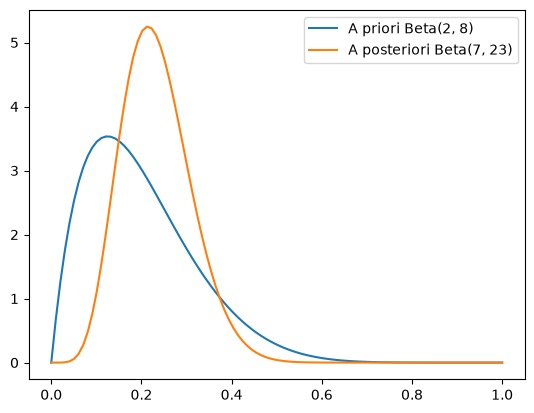

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

prior = beta(2, 8)
post_a = beta(2 + 5, 8 + 15)

print(f"3. a) Beta(7, 23) | medie: {post_a.mean():.5f}")

x = np.linspace(0, 1, 100)
plt.plot(x, prior.pdf(x), label="A priori Beta(2, 8)")
plt.plot(x, post_a.pdf(x), label="A posteriori Beta(7, 23)")
plt.legend()
plt.show()